# 01 · Pré-processamento dos dados de CVLI em Alagoas

Este notebook prepara a base de microdados de **Crimes Violentos Letais Intencionais (CVLI)** da Secretaria de Segurança Pública de Alagoas (portal *Alagoas em Dados*) para a análise exploratória (notebook 02) e a análise por população (notebook 03).

**O que é feito aqui**

1. Carga da base e primeira inspeção.
2. Recorte temporal (até 31/12/2025).
3. Estrutura, valores ausentes e duplicatas.
4. Tratamento da idade (conversão numérica e faixas etárias).
5. Primeira análise: a distribuição etária das vítimas mudou ao longo do tempo?

**Arquivos:** entrada em `../dados_brutos/cvli_dados.csv`. A base tratada completa (com local, período do dia e demais variáveis derivadas) é gerada ao final do notebook 02, em `../dados_tratados/`.

## 0. Preparação do ambiente

In [1]:
!pip install pandas
!pip install numpy
!pip install matplotlib


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 1. Carga da base

A base original traz uma linha por vítima, com data, hora, município, bairro, sexo, cor/raça, idade, instrumento, local, ocupação e escolaridade.

In [3]:
df = pd.read_csv('../dados_brutos/cvli_dados.csv')

In [4]:
df.head(5)

,ID_CONTROLE,SUBJETIVIDADE,SUBJETIVIDADE COMPLEMENTAR,DATA DO FATO,HORA DO FATO,CIDADE DO FATO,BAIRRO DO FATO,SEXO DA VITIMA,COR/RACA DA VITIMA,IDADE DA VITIMA,INSTRUMENTO UTILIZADO,LOCAL DO FATO,OCUPACAO VITIMA,ESCOLARIDADE VITIMA
0,46,CVLI,Homicídio,03/01/2012,12:30,Maceió,Benedito Bentes,Masculino,NI,24,PAF/B,Local de Trabalho,NI,NI
1,47,CVLI,Homicídio,03/01/2012,13:00,Palmeira dos Índios,Palmeira de Fora,Masculino,Parda,51,BRANCA,Próximo de Casa,Servidor Público,Superior
2,48,CVLI,Homicídio,03/01/2012,13:15,Maceió,Cidade Universitária,Masculino,Amarela,24,PAF,Via Pública,NI,NI
3,63,CVLI,Homicídio,07/01/2012,08:00,União dos Palmares,Zona Rural,Masculino,Parda,NI,ESPANCAMENTO,Vegetação,NI,NI
4,59,CVLI,Homicídio,06/01/2012,13:00,Maceió,Tabuleiro do Martins,Masculino,NI,21,PAF,Via Pública,NI,NI


In [5]:
df.tail()

,ID_CONTROLE,SUBJETIVIDADE,SUBJETIVIDADE COMPLEMENTAR,DATA DO FATO,HORA DO FATO,CIDADE DO FATO,BAIRRO DO FATO,SEXO DA VITIMA,COR/RACA DA VITIMA,IDADE DA VITIMA,INSTRUMENTO UTILIZADO,LOCAL DO FATO,OCUPACAO VITIMA,ESCOLARIDADE VITIMA
21289,66914,CVLI,Homicídio,31/05/2026,22:53,Piaçabuçu,Centro,Masculino,Parda,37,PAF,Residência,NI,Médio
21290,66858,CVLI,Homicídio,26/05/2026,12:46,Maceió,Benedito Bentes,Masculino,Parda,22,PAF,Residência,NI,NI
21291,66817,CVLI,Homicídio,22/05/2026,08:06,Matriz de Camaragibe,Centro,Masculino,Parda,29,BRANCA,Via Pública,NI,NI
21292,66908,CVLI,Homicídio,31/05/2026,04:50,Maceió,Tabuleiro do Martins,Masculino,Parda,24,PAF,Via Pública,NI,NI
21293,66824,CVLI,Homicídio,23/05/2026,04:09,Messias,Centro,Masculino,Parda,40,PAF,Residência,NI,NI


## 2. Recorte temporal

O recorte vai até **31/12/2025**. A base também tem registros de 2026 (até maio), mas esse ano está incompleto e distorceria as comparações anuais. Por isso 2025 é o último ano com cobertura completa. Além disso, como 2012 também está fora da série comparável (ver seção 5), as comparações entre anos usam 2013–2025.

In [6]:
df['DATA DO FATO'] = pd.to_datetime(df['DATA DO FATO'], dayfirst= True)

In [7]:
df.head()

,ID_CONTROLE,SUBJETIVIDADE,SUBJETIVIDADE COMPLEMENTAR,DATA DO FATO,HORA DO FATO,CIDADE DO FATO,BAIRRO DO FATO,SEXO DA VITIMA,COR/RACA DA VITIMA,IDADE DA VITIMA,INSTRUMENTO UTILIZADO,LOCAL DO FATO,OCUPACAO VITIMA,ESCOLARIDADE VITIMA
0,46,CVLI,Homicídio,2012-01-03,12:30,Maceió,Benedito Bentes,Masculino,NI,24,PAF/B,Local de Trabalho,NI,NI
1,47,CVLI,Homicídio,2012-01-03,13:00,Palmeira dos Índios,Palmeira de Fora,Masculino,Parda,51,BRANCA,Próximo de Casa,Servidor Público,Superior
2,48,CVLI,Homicídio,2012-01-03,13:15,Maceió,Cidade Universitária,Masculino,Amarela,24,PAF,Via Pública,NI,NI
3,63,CVLI,Homicídio,2012-01-07,08:00,União dos Palmares,Zona Rural,Masculino,Parda,NI,ESPANCAMENTO,Vegetação,NI,NI
4,59,CVLI,Homicídio,2012-01-06,13:00,Maceió,Tabuleiro do Martins,Masculino,NI,21,PAF,Via Pública,NI,NI


In [ ]:
print("Linhas antes do recorte:", len(df))
print("Período coberto:", df["DATA DO FATO"].min().date(), "a", df["DATA DO FATO"].max().date())
print("Linhas posteriores a 31/12/2025 (serão descartadas):", (df["DATA DO FATO"] > "2025-12-31").sum())

In [8]:
df = df[df['DATA DO FATO'] <= '2025-12-31']

In [9]:
df.head()

,ID_CONTROLE,SUBJETIVIDADE,SUBJETIVIDADE COMPLEMENTAR,DATA DO FATO,HORA DO FATO,CIDADE DO FATO,BAIRRO DO FATO,SEXO DA VITIMA,COR/RACA DA VITIMA,IDADE DA VITIMA,INSTRUMENTO UTILIZADO,LOCAL DO FATO,OCUPACAO VITIMA,ESCOLARIDADE VITIMA
0,46,CVLI,Homicídio,2012-01-03,12:30,Maceió,Benedito Bentes,Masculino,NI,24,PAF/B,Local de Trabalho,NI,NI
1,47,CVLI,Homicídio,2012-01-03,13:00,Palmeira dos Índios,Palmeira de Fora,Masculino,Parda,51,BRANCA,Próximo de Casa,Servidor Público,Superior
2,48,CVLI,Homicídio,2012-01-03,13:15,Maceió,Cidade Universitária,Masculino,Amarela,24,PAF,Via Pública,NI,NI
3,63,CVLI,Homicídio,2012-01-07,08:00,União dos Palmares,Zona Rural,Masculino,Parda,NI,ESPANCAMENTO,Vegetação,NI,NI
4,59,CVLI,Homicídio,2012-01-06,13:00,Maceió,Tabuleiro do Martins,Masculino,NI,21,PAF,Via Pública,NI,NI


Após o recorte, a base tem **14 colunas e 20.928 linhas**.

In [10]:
df.shape

(20928, 14)

> **Síntese da etapa 2.** A base bruta tem 21.294 registros, de 01/01/2012 a 31/05/2026. O recorte até 2025 descarta 366 linhas de 2026 (ano incompleto) e deixa 20.928 registros e 14 colunas. A coluna `SUBJETIVIDADE` tem um único valor (`CVLI`), portanto não diferencia casos; quem separa o tipo de crime é `SUBJETIVIDADE COMPLEMENTAR`.

## 3. Estrutura, valores ausentes e duplicatas

Nenhuma coluna tem valores nulos para o pandas, mas isso não significa que todas as linhas tenham informação de fato: a base usa o marcador `NI` (não informado) e variantes no lugar de células vazias.

In [11]:
df.info()

<class 'pandas.DataFrame'>
Index: 20928 entries, 0 to 21278
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   ID_CONTROLE                 20928 non-null  int64         
 1   SUBJETIVIDADE               20928 non-null  str           
 2   SUBJETIVIDADE COMPLEMENTAR  20928 non-null  str           
 3   DATA DO FATO                20928 non-null  datetime64[us]
 4   HORA DO FATO                20928 non-null  str           
 5   CIDADE DO FATO              20928 non-null  str           
 6   BAIRRO DO FATO              20928 non-null  str           
 7   SEXO DA VITIMA              20928 non-null  str           
 8   COR/RACA DA VITIMA          20928 non-null  str           
 9   IDADE DA VITIMA             20928 non-null  str           
 10  INSTRUMENTO UTILIZADO       20928 non-null  str           
 11  LOCAL DO FATO               20928 non-null  str           
 12  OCUPAC

In [12]:
df.isnull().sum()

ID_CONTROLE                   0
SUBJETIVIDADE                 0
SUBJETIVIDADE COMPLEMENTAR    0
DATA DO FATO                  0
HORA DO FATO                  0
CIDADE DO FATO                0
BAIRRO DO FATO                0
SEXO DA VITIMA                0
COR/RACA DA VITIMA            0
IDADE DA VITIMA               0
INSTRUMENTO UTILIZADO         0
LOCAL DO FATO                 0
OCUPACAO VITIMA               0
ESCOLARIDADE VITIMA           0
dtype: int64

In [13]:
colunas_categoricas = [
    "SUBJETIVIDADE",
    "SUBJETIVIDADE COMPLEMENTAR",
    "CIDADE DO FATO",
    "SEXO DA VITIMA",
    "COR/RACA DA VITIMA",
    "INSTRUMENTO UTILIZADO",
    "LOCAL DO FATO",
    "OCUPACAO VITIMA",
    "ESCOLARIDADE VITIMA"
]

for coluna in colunas_categoricas:
    print(f"\n{coluna}")
    print(df[coluna].value_counts(dropna=False))


SUBJETIVIDADE
SUBJETIVIDADE
CVLI    20928
Name: count, dtype: int64

SUBJETIVIDADE COMPLEMENTAR
SUBJETIVIDADE COMPLEMENTAR
Homicídio                          19898
Roubo com Resultado Morte            572
Feminicídio                          306
Lesão Corporal Seguida de Morte      134
Estupro com Resultado Morte           15
Infanticídio                           3
Name: count, dtype: int64

CIDADE DO FATO
CIDADE DO FATO
Maceió                6906
Arapiraca             1497
Rio Largo              869
União dos Palmares     470
Marechal Deodoro       451
                      ... 
Minador do Negrão       13
Belo Monte              10
Palestina                9
Mar Vermelho             8
Pindoba                  7
Name: count, Length: 102, dtype: int64

SEXO DA VITIMA
SEXO DA VITIMA
Masculino    19539
Feminino      1389
Name: count, dtype: int64

COR/RACA DA VITIMA
COR/RACA DA VITIMA
Parda       15806
Branca       2421
Preta        1578
NI           1047
Amarela        68
Indígena     

In [ ]:
# Marcadores de ausência escritos como texto (a base não usa células vazias)
marcadores = ["NI", "Não Informado", "Sem Informação"]
cols_ni = ["IDADE DA VITIMA", "COR/RACA DA VITIMA", "INSTRUMENTO UTILIZADO",
           "LOCAL DO FATO", "OCUPACAO VITIMA", "ESCOLARIDADE VITIMA"]

ni = pd.DataFrame({
    "ausentes": [df[c].astype(str).str.strip().isin(marcadores).sum() for c in cols_ni]
}, index=cols_ni)
ni["% da base"] = (ni["ausentes"] / len(df) * 100).round(1)
display(ni.sort_values("ausentes", ascending=False))

In [ ]:
print("IDs de controle duplicados:", df["ID_CONTROLE"].duplicated().sum())
print("Linhas totalmente idênticas:", df.duplicated().sum())
print("Linhas idênticas em tudo, exceto o ID:", df.drop(columns="ID_CONTROLE").duplicated().sum())

> **Síntese da etapa 3.**
> - **Ausentes:** escolaridade (74,4%) e ocupação (67,8%) têm ausência muito alta e não servem para tirar conclusões. Cor/raça (5,0%), idade (2,1%), instrumento (1,9%) e local (0,5%) têm cobertura boa. Município, bairro e hora estão preenchidos.
> - **Duplicatas:** não há IDs repetidos nem linhas totalmente idênticas. Existem 37 linhas iguais em tudo menos o ID; elas **foram mantidas**, porque podem ser vítimas diferentes do mesmo evento (por exemplo, uma chacina).
> - **Decisão:** o tratamento de `NI` é feito variável a variável, quando ela é usada (idade na seção 4; local, cor/raça e instrumento no notebook 02).

## 4. Tratamento da idade

A idade é a variável numérica central do perfil das vítimas. Os valores mais frequentes mostram que a violência letal se concentra em jovens: as idades de 17 a 24 anos lideram a contagem, com pico aos 20 anos.

In [14]:
print(df["IDADE DA VITIMA"].value_counts(dropna=False))

IDADE DA VITIMA
20     1033
19     1015
21      987
18      986
22      962
       ... 
90        2
100       1
83        1
102       1
81        1
Name: count, Length: 96, dtype: int64


In [15]:
idade_numerica = pd.to_numeric(
    df["IDADE DA VITIMA"],
    errors="coerce"
)

valores_invalidos = df.loc[
    idade_numerica.isna(),
    "IDADE DA VITIMA"
]

print(valores_invalidos.value_counts())

IDADE DA VITIMA
NI    440
Name: count, dtype: int64


As **440 vítimas** com idade `NI` (único valor não numérico da coluna) foram convertidas em `NaN`, para que não distorçam médias e quartis. Elas permanecem na base e continuam contando nas demais análises.

In [16]:
df["IDADE_NUMERICA"] = pd.to_numeric(
    df["IDADE DA VITIMA"],
    errors="coerce"
)

### Faixas etárias

Faixas usadas: 0–11 (infância), 12–17 (adolescência), 18–24, 25–34, 35–44, 45–59 e 60+ (idosos).

In [17]:
faixas = [-1, 11, 17, 24, 34, 44, 59, np.inf]

rotulos = [
    "0–11", "12–17", "18–24",
    "25–34", "35–44", "45–59", "60+"
]

df["FAIXA_ETARIA"] = pd.cut(
    df["IDADE_NUMERICA"],
    bins=faixas,
    labels=rotulos
)

distribuicao = df["FAIXA_ETARIA"].value_counts(
    sort=False,
    dropna=False
)

print(distribuicao)

FAIXA_ETARIA
0–11      102
12–17    2145
18–24    6771
25–34    5920
35–44    3052
45–59    1902
60+       596
NaN       440
Name: count, dtype: int64


In [18]:
media = df['IDADE_NUMERICA'].mean()
median = df['IDADE_NUMERICA'].median()
mode = df['IDADE_NUMERICA'].mode()
quartis = df['IDADE_NUMERICA'].quantile([0.25, 0.5, 0.75])



print("Media:", media)
print("Moda:", mode)
print("Mediana:", median)
print("Quartis:", quartis)

Media: 29.43781725888325
Moda: 0    20.0
Name: IDADE_NUMERICA, dtype: float64
Mediana: 26.0
Quartis: 0.25    20.0
0.50    26.0
0.75    36.0
Name: IDADE_NUMERICA, dtype: float64


> **Síntese da etapa 4.** A idade média é 29,4 anos, a mediana 26 e a moda 20; metade das vítimas tem entre 20 e 36 anos (quartis 20 e 36), e a faixa vai de 0 a 102 anos. A média acima da mediana indica cauda de vítimas mais velhas. Por faixa, 18–24 anos concentra 32,4% das vítimas e 25–34 anos outros 28,3%: juntas, as duas faixas respondem por 60,7%. Adolescentes de 12–17 anos são 10,3% e idosos (60+) 2,8%. Os 2,1% sem idade ficam como `NaN`.

## 5. A distribuição etária mudou ao longo do tempo?

A tabela abaixo calcula a participação percentual de cada faixa etária no total de registros de cada ano. Os casos com idade desconhecida entram no denominador, então cada linha soma um pouco menos de 100%. A série começa em 2013 porque 2012 não tem cobertura regular.

In [19]:
df_analise = df[
    df["DATA DO FATO"].dt.year.between(2013, 2025)
].copy()

df_analise["ANO"] = df_analise["DATA DO FATO"].dt.year

tabela = pd.crosstab(
    df_analise["ANO"],
    df_analise["FAIXA_ETARIA"],
    normalize="index"
) * 100

display(tabela.round(2))

FAIXA_ETARIA,0–11,12–17,18–24,25–34,35–44,45–59,60+
ANO,,,,,,,
2013,0.72,12.58,33.62,29.32,13.67,8.05,2.04
2014,0.43,12.83,32.42,27.59,15.10,8.44,3.18
2015,0.48,12.47,32.34,28.88,12.77,10.32,2.74
2016,0.46,12.67,31.93,27.76,15.21,9.37,2.60
2017,0.63,12.95,36.10,24.81,13.87,7.94,3.68
2018,0.37,11.57,34.25,25.90,14.78,10.00,3.13
2019,0.66,8.62,33.46,26.15,18.56,9.65,2.91
2020,0.33,8.73,36.16,27.59,14.29,9.55,3.35
2021,0.85,7.77,32.10,31.72,15.06,9.47,3.03


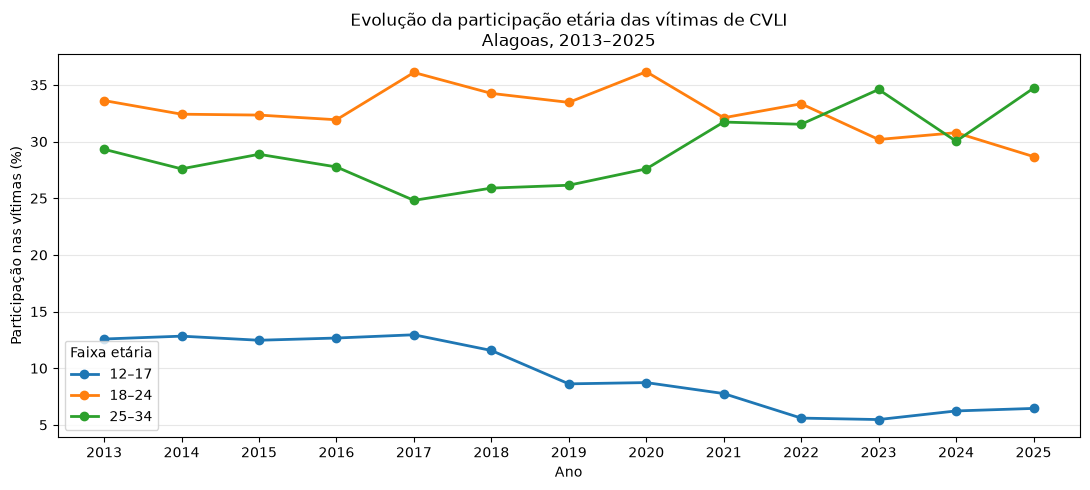

In [20]:
faixas_selecionadas = ["12–17", "18–24", "25–34"]

ax = tabela[faixas_selecionadas].plot(
    kind="line",
    figsize=(11, 5),
    marker="o",
    linewidth=2
)

ax.set_title(
    "Evolução da participação etária das vítimas de CVLI\n"
    "Alagoas, 2013–2025"
)

ax.set_xlabel("Ano")
ax.set_ylabel("Participação nas vítimas (%)")
ax.set_xticks(tabela.index)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Faixa etária")

plt.tight_layout()
plt.savefig("evolucao_faixas_etarias.png", dpi=300)
plt.show()

> **Síntese da etapa 5.** A faixa de **12–17 anos caiu pela metade** (12,6% das vítimas em 2013 para 6,5% em 2025), e a de **18–24 anos também recuou** (33,6% para 28,7%). Em sentido contrário, a faixa de **25–34 anos cresceu** (29,3% para 34,7%) e passou a ser a mais numerosa em 2025. Ou seja, a queda dos homicídios foi acompanhada de um envelhecimento do perfil das vítimas: menos adolescentes e jovens, proporcionalmente mais adultos. Esse resultado é testado estatisticamente no notebook 02 (seção 12, teste 7).

## Síntese geral do pré-processamento

| Decisão | Justificativa |
|---|---|
| Recorte até 31/12/2025 | 2026 está incompleto (até maio) |
| Comparações entre anos de 2013 a 2025 | 2012 não tem série regular |
| `NI` tratado variável a variável | A base usa texto, não células vazias; a ausência varia de 0,5% a 74% |
| Escolaridade e ocupação fora das conclusões | Mais de 65% de ausência |
| Idade `NI` → `NaN` (440 vítimas) | Evita distorcer média e quartis, sem descartar a vítima |
| Linhas duplicadas exceto o ID mantidas (37) | Podem ser vítimas distintas do mesmo evento |
| Faixas etárias de 7 categorias | Permitem comparar o perfil ao longo dos anos |

**Próximos passos:** o notebook 02 faz a análise exploratória e inferencial (perguntas de pesquisa, estatística descritiva, intervalos de confiança e testes de hipóteses), e o notebook 03 refaz as comparações em taxa por 100 mil habitantes.